# Práctica 2 — Introducción al aprendizaje supervisado

**Machine Learning · Máster Universitario en Inteligencia Artificial · curso 2026/2027**

Grupo: *4* · Integrantes: *Carlos Chapman Peña*, *Miguel Ángel Gordillo Masero*, *María Xiaolan Ríos Díaz*, *Pablo Sola Díaz*

---

Cuaderno **de partida**. La primera celda de código fija vuestro grupo y vuestra semilla y carga
los datos; la última escribe los dos ficheros que subís a Kaggle. **Entre medias, el cuaderno es
vuestro**: los títulos de los ejercicios solo marcan el orden. La interpretación va en celdas
Markdown, no en comentarios de Python.

## 0. Entorno, semilla y datos

Declarad `GRUPO` y `SEMILLA` antes de nada. **Toda la aleatoriedad del cuaderno sale de
`SEMILLA`**: las particiones de la validación, los desempates y cualquier `random_state`.

In [1]:
# --- Práctica 2: grupo, semilla, entorno y datos --------------------------------
GRUPO = 4        # vuestro número de grupo (entero)
SEMILLA = 67      # vuestra semilla (entero): toda la aleatoriedad sale de aquí

import os, sys, platform
import numpy as np, pandas as pd, matplotlib, sklearn, scipy
import matplotlib.pyplot as plt

assert isinstance(GRUPO, int) and isinstance(SEMILLA, int), "Declarad GRUPO y SEMILLA (enteros) antes de seguir."

DATOS = os.path.join("..", "Datos")                  # relativa a este cuaderno
sys.path.insert(0, os.path.join("..", "Codigo"))     # código proporcionado por el curso
from oner import OneRClassifier, OneRRegressor
from comprobar_estimador import comprobar_estimador

ciber_train = pd.read_csv(os.path.join(DATOS, "ciber_train.csv"))
ciber_test = pd.read_csv(os.path.join(DATOS, "ciber_test.csv"))
latencia_train = pd.read_csv(os.path.join(DATOS, "latencia_train.csv"))
latencia_test = pd.read_csv(os.path.join(DATOS, "latencia_test.csv"))

X_CIBER = [c for c in ciber_test.columns if c != "id"]          # características de ciber
X_LATENCIA = [c for c in latencia_test.columns if c != "id"]    # características de latencia

print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("GRUPO       ", GRUPO, "· SEMILLA", SEMILLA)
print("ciber       ", ciber_train.shape, ciber_test.shape)
print("latencia    ", latencia_train.shape, latencia_test.shape)

python       3.13.5
numpy        2.1.3
pandas       2.2.3
scikit-learn 1.6.1
GRUPO        4 · SEMILLA 67
ciber        (5000, 13) (5000, 12)
latencia     (5000, 11) (3000, 10)


## Ejercicio 1. Cómo vais a medir

*(TODO)*

### 1(a) Datos de ciber_train

In [ ]:
ciber_train.info()
#Contar valores nulos
nulos_ciber = ciber_train.isnull().sum()
print(nulos_ciber)


### 1(a) Datos de latencia_train

In [2]:
# Información general
latencia_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             5000 non-null   object 
 1   block_size     5000 non-null   int64  
 2   n_jobs         5000 non-null   int64  
 3   iodepth        5000 non-null   int64  
 4   read_fraction  5000 non-null   int64  
 5   load_type      5000 non-null   object 
 6   io_type        5000 non-null   object 
 7   raid           5000 non-null   object 
 8   n_disks        5000 non-null   int64  
 9   device_type    5000 non-null   object 
 10  latency_ns     5000 non-null   float64
dtypes: float64(1), int64(5), object(5)
memory usage: 429.8+ KB


Con .info() comprobamos que no hay valores nulos en ninguna de las características del conjunto de datos y podemos ver el tipo de dato de cada una.

In [3]:
display(latencia_train.describe())

nominales = ['load_type', 'io_type', 'raid', 'device_type']
for col in nominales:
    print(latencia_train[col].value_counts())
    print("\n")

,block_size,n_jobs,iodepth,read_fraction,n_disks,latency_ns
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,208.576000,16.88100,16.934000,40.684000,17.994000,2.407129e+07
std,301.354501,15.54494,10.060412,36.357097,6.719598,9.319971e+07
min,4.000000,1.00000,1.000000,0.000000,3.000000,1.143315e+05
25%,16.000000,6.00000,8.000000,0.000000,12.000000,6.099692e+05
50%,64.000000,12.00000,15.000000,35.000000,20.000000,1.240523e+06
75%,256.000000,20.00000,27.000000,75.000000,24.000000,8.127825e+06
max,1024.000000,64.00000,32.000000,100.000000,24.000000,1.262194e+09


load_type
random        3270
sequential    1730
Name: count, dtype: int64


io_type
write    2980
read     2020
Name: count, dtype: int64


raid
4+1    2180
2+2     600
4+2     565
8+2     560
1+1     560
2+1     535
Name: count, dtype: int64


device_type
nvme    4210
hdd      790
Name: count, dtype: int64




Con .describe() mostramos un resumen estadístico de las características, que incluye la media, la desviación típica, los cuartiles y los valores mínimos y máximos. A partir de estos últimos, podemos observar que las características tienen escalas bastante diferentes. Por ejemplo, `block_size` toma valores entre 4 y 1024, mientras que los valores de `latency_ns` son mucho más elevados, llegando hasta 1.262.194.000. Otras variables, como `n_jobs` e `iodepth`, tienen rangos más reducidos. Estas diferencias de escala deben tenerse en cuenta durante el preprocesamiento, porque puede ser necesario aplicar técnicas de normalización o estandarización antes de entrenar el modelo.

Por otro lado, las variables categóricas muestran distribuciones desiguales: en `load_type` predomina random (3.270) frente a sequential (1.730); en `io_type` también hay más registros de write (2.980) que de read (2.020); en `raid` destaca 4+1 como la configuración más frecuente (2.180), mientras que las demás tienen frecuencias similares, con valores entre 535 y 600 registros; y en `device_type` domina claramente nvme (4.210) sobre hdd (790).

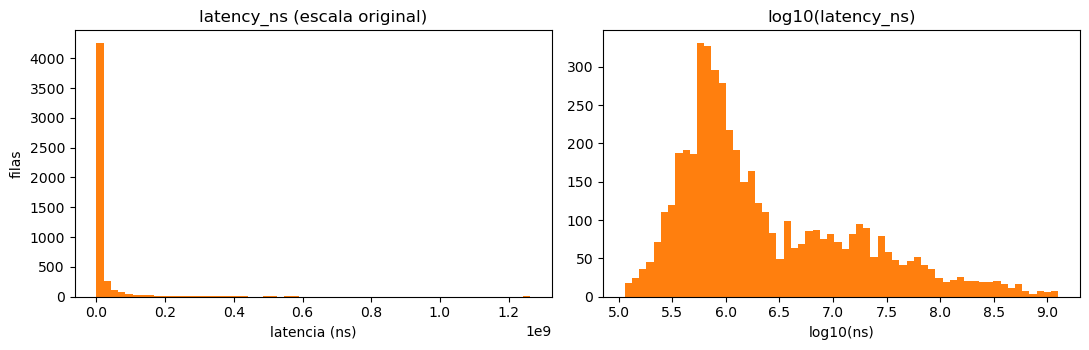

In [4]:
# Distribución de la variable objetivo (latencia_ns) en train
y = latencia_train["latency_ns"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(y, bins=60, color="C1"); ax[0].set_title("latency_ns (escala original)")
ax[0].set_xlabel("latencia (ns)"); ax[0].set_ylabel("filas")
ax[1].hist(np.log10(y), bins=60, color="C1"); ax[1].set_title("log10(latency_ns)")
ax[1].set_xlabel("log10(ns)")
plt.tight_layout(); plt.show()

En las gráficas podemos observar la distribución de la variable objetivo (`latency_ns`) tanto en su escala original como después de aplicar la transformación logarítmica `log10`.

En la escala original, la distribución es muy asimétrica hacia la derecha, ya que la mayoría de las observaciones tienen valores bajos, mientras que existen algunos valores de latencia muy altos que alargan la distribución.

Al aplicar la transformación logarítmica, reducimos esta asimetría y visualizamos mejor la distribución de los datos. De esta forma, podemos observar con más claridad las diferencias entre las latencias y conocer mejor el comportamiento de la variable antes de utilizarla en el modelo.

In [5]:
# Cuánto varían las cinco ejecuciones de una misma configuración

# Se definen las columnas que representan la "configuración" (todas menos 'id' y 'latency_ns')
configuracion = [c for c in latencia_train.columns if c not in ['id', 'latency_ns']]

grupos_lat = latencia_train.groupby(configuracion)["latency_ns"]
ratio_max_min = grupos_lat.max() / grupos_lat.min()
std_log10 = grupos_lat.apply(lambda s: np.log10(s).std(ddof=1))

resumen_var = pd.DataFrame({
    "ratio_max_min": ratio_max_min,
    "std_log10_ns": std_log10,
})
print("Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):")
display(
    resumen_var.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T[[
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "90%",
        "max",
    ]]
)

# Ejemplo de una configuración y sus 5 latencias distintas
ejecuciones = grupos_lat.size()
ejemplo = ejecuciones[ejecuciones == 5].index[0]
ejemplo = (latencia_train[configuracion] == ejemplo).all(axis=1)
ejemplo = latencia_train[ejemplo][['block_size', 'n_jobs', 'iodepth', 'read_fraction', 'load_type', 'io_type', 'raid', 'n_disks', 'device_type', 'latency_ns']]
print("\nEjemplo de las 5 ejecuciones para una misma configuración:")
display(ejemplo)
latencias = ejemplo['latency_ns']

Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):


,count,mean,std,min,25%,50%,75%,90%,max
ratio_max_min,1000.0,1.287067,1.139653,1.000245,1.021795,1.068416,1.223296,1.572391,26.24800
std_log10_ns,1000.0,0.030703,0.053001,0.000044,0.003833,0.011891,0.035911,0.080515,0.62397



Ejemplo de las 5 ejecuciones para una misma configuración:


,block_size,n_jobs,iodepth,read_fraction,load_type,io_type,raid,n_disks,device_type,latency_ns
408,4,2,11,23,random,read,4+1,24,nvme,121127.5
543,4,2,11,23,random,read,4+1,24,nvme,117519.0
3819,4,2,11,23,random,read,4+1,24,nvme,116699.0
4349,4,2,11,23,random,read,4+1,24,nvme,119568.5
4960,4,2,11,23,random,read,4+1,24,nvme,118525.0


La primera tabla muestra cuánto varía la latencia (`latency_ns`) entre las 5 repeticiones de cada una de las 1.000 configuraciones únicas. Para ello, se utilizan dos métricas:
* **`ratio_max_min`**: indica cuántas veces mayor es la latencia máxima respecto a la mínima de una misma configuración. Un valor cercano a 1 significa que las ejecuciones han tenido resultados muy similares, mientras que valores más altos indican una mayor diferencia entre ellas.
* **`std_log10_ns`**: mide la desviación típica de `log10(latency_ns)` dentro de cada configuración. Permite analizar la variabilidad teniendo en cuenta que las diferencias de latencia pueden ser multiplicativas y no siempre siguen una distribución simétrica.

### Resumen de variabilidad

En la mayoría de las configuraciones se observa una variabilidad bastante baja entre las cinco repeticiones. La mediana (`50%`) de `ratio_max_min` es 1.068, lo que significa que, en un caso típico, la ejecución más lenta tarda aproximadamente un 6,8 % más que la más rápida. Además, en el `75 %` de las configuraciones el ratio no supera 1.223. La mediana de `std_log10_ns` también es baja (0.0119), lo que confirma que, por lo general, las distintas ejecuciones ofrecen resultados bastante similares.

Sin embargo, hay algunas configuraciones que presentan diferencias mucho más importantes entre repeticiones. Esto se refleja en que la media de `ratio_max_min` (1.287) es superior a su mediana (1.068), lo que indica que existen algunos valores extremos que elevan el promedio. Aunque la mayoría de los casos son bastante estables, el percentil 90 alcanza 1.572 y el valor máximo llega a 26.248. Esto significa que, en alguna configuración concreta, la ejecución más lenta ha tardado más de 26 veces que la más rápida.

Estos resultados muestran que una misma configuración no siempre produce exactamente la misma latencia, ya que existen variaciones entre sus distintas ejecuciones, probablemente debido a la existencia de ruido.

### Ejemplo

La segunda tabla muestra un ejemplo concreto de la variabilidad de la latencia en las cinco ejecuciones de una configuración. En este caso, se puede ver que no varía demasiado.

**¿Qué hace difícil este problema?**

La predicción de la latencia es difícil debido a diferentes cosas:

- **Asimetría de su distribución:** La variable objetivo tiene un rango de valores muy amplio (desde aproximadamente $10^5$ hasta $10^9$ ns) y una distribución muy sesgada. Esto es importante porque el $MAE_{\log}$ calcula el error absoluto medio sobre el logaritmo decimal de la latencia:
   $$MAE_{\log} = \frac{1}{n} \sum_{i=1}^{n} \vert{}\log_{10} y_i - \log_{10} \hat{y}_i\vert{}$$
   A diferencia del $MAE$, que mide las diferencias absolutas en las unidades originales y hace que los errores en valores más altos tengan mayor peso, el $MAE_{\log}$ tiene en cuenta los errores relativos. De esta forma, evita que las latencias más elevadas condicionen tanto el resultado de la evaluación. Esto significa que un error multiplicativo del mismo tamaño (por ejemplo, desviarse por un factor de 1.26) recibe la misma penalización, independientemente de si se produce en latencias de microsegundos o de milisegundos.

- **La variabilidad entre ejecuciones de una misma configuración:** Como hemos visto en la tabla anterior, los resultados de las cinco repeticiones de una misma configuración varían un poco debido al ruido, lo que planteará la decisión de si entrenar el modelo con todas las filas o calcular un valor medio que represente cada configuración en el Ejercicio 3.

- **Que puedan existir relaciones no lineales e interacciones entre las características:** El rendimiento del almacenamiento depende de varios factores que se influyen entre sí, como el tamaño de bloque, la profundidad de cola, el número de hilos y el tipo de RAID. Por ello, es necesario utilizar modelos que puedan detectar cómo afectan sus distintas combinaciones al rendimiento.

- **Hay variables numéricas y categóricas:** Como el conjunto de datos combina ambos tipos de variables, es necesario realizar un preprocesamiento adecuado antes de entrenar el modelo. Para ello, se deberán transformar las variables categóricas mediante técnicas de codificación y escalar las numéricas para evitar que unas tengan más peso que otras. Esto es muy importante en KNN porque utiliza distancias para determinar qué configuraciones son más similares entre sí.

### 1(b) Protocolos de validación de latencia_train

In [6]:
from sklearn.model_selection import GroupKFold, KFold

# Identificador de grupo: cada configuración única de hardware/carga (1.000 grupos)
cols_config = [c for c in X_LATENCIA]
grupos_latencia = latencia_train.groupby(cols_config, dropna=False).ngroup()

# Métrica oficial de la competición: error absoluto medio en log10(latency_ns)
def mae_log(y_true, y_pred):
  y_true = np.asarray(y_true, dtype=float)
  y_pred = np.asarray(y_pred, dtype=float)
  assert np.all(y_true > 0) and np.all(y_pred > 0), (
      "y_true y y_pred deben ser positivos"
  )
  return float(np.mean(np.abs(np.log10(y_true) - np.log10(y_pred))))


# Esquemas de validación candidatos (K = 5 particiones)
cv_agrupada = GroupKFold(n_splits=5)
cv_aleatoria = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Comprobación de solapamiento de configuraciones entre train y validación
solap_agrupada = []
solap_aleatoria = []

for tr_idx, va_idx in cv_agrupada.split(
    latencia_train, latencia_train["latency_ns"], groups=grupos_latencia
):
  solap_agrupada.append(
      len(
          set(grupos_latencia.iloc[tr_idx]) & set(grupos_latencia.iloc[va_idx])
      )
  )

for tr_idx, va_idx in cv_aleatoria.split(latencia_train):
  solap_aleatoria.append(
      len(
          set(grupos_latencia.iloc[tr_idx]) & set(grupos_latencia.iloc[va_idx])
      )
  )

print(
    "Configuraciones compartidas train/val por fold (GroupKFold, K=5):",
    solap_agrupada,
)
print(
    "Configuraciones compartidas train/val por fold (KFold por filas, K=5):",
    solap_aleatoria,
)

Configuraciones compartidas train/val por fold (GroupKFold, K=5): [0, 0, 0, 0, 0]
Configuraciones compartidas train/val por fold (KFold por filas, K=5): [684, 681, 677, 669, 657]


### Esquemas de validación que vamos a probar
Utilizamos 5 particiones ($K = 5$) sobre el conjunto de entrenamiento y comparamos dos formas de realizar la validación:

- **1º Validación cruzada aleatoria por filas:** divide las 5.000 filas al azar sin tener en cuenta las configuraciones, por lo que una misma configuración puede aparecer tanto en entrenamiento como en validación.


- **2º Validación cruzada por grupos:** agrupa las filas según su configuración, definida por sus 9 características. Así, las cinco ejecuciones de una configuración caen siempre en la misma partición, evitando que una configuración aparezca tanto en entrenamiento como en validación.

### Métrica utilizada
La métrica que usaremos para medir la calidad del modelo será $MAE_{\log}$, que es la de la competición. Cuanto menor sea su valor, mejor será el resultado, siempre que las predicciones sean positivas:
$$MAE_{\log} = \frac{1}{n} \sum_{i=1}^{n} \vert{}\log_{10} y_i - \log_{10} \hat{y}_i\vert{}$$


### Elección y justificación
Al validar sin agrupar por configuración, obtendremos un $MAE_{\log}$ más bajo que el de la validación cuando se agrupan, siendo más optimista. Esto es debido a lo siguiente: 

De cada grupo de configuración (denotemos a un grupo de ejemplo como $G1$), tenemos 5 ejecuciones distintas. Si en el grupo de entrenamiento de $G1$ caen solo dos ejecuciones ($G1_{1}$ y $G1_{2}$), las otras tres caerán en el grupo de validación ($G1_{3}$, $G1_{4}$ y $G1_{5}$). Entonces, cuando el modelo reciba, por ejemplo $G1_{3}$, verá que está a distancia cero de $G1_{1}$ y $G1_{2}$, por lo que estará evaluándose sobre configuraciones que ya conoce.

Además, con el código anterior comprobamos que, agrupando por configuración, no se comparte ninguna configuración entre los conjuntos de entrenamiento y validación en ninguna de las cinco particiones. En cambio, sin agrupar, se comparten entre 657 y 684 configuraciones en cada partición, lo que confirma que existe un solapamiento importante entre ambos conjuntos.

Sin embargo, el conjunto de test contiene 600 configuraciones nuevas (3000 filas) que no aparecen en el entrenamiento. Por esto, seleccionaremos la validación cruzada por grupos con 5 particiones, ya que reproduce mejor las condiciones que encontraremos en la competición. Aunque el error obtenido sea algo mayor que con la división aleatoria por filas, tendremos una estimación más realista de cómo se comportará el modelo con configuraciones que no ha visto. Con 5 particiones, en cada una deja unas 200 configuraciones en validación (unas 1000 filas) y unas 800 configuraciones en entrenamiento (unas 4000 filas).

In [ ]:
""" 
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, StratifiedGroupKFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Variables que vamos a utilizar
nominales = ["load_type", "io_type", "raid", "device_type"]
numericas = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]

lat = latencia_train.copy()
lat["ylog"] = np.log10(lat["latency_ns"])

# Identificamos las configuraciones
lat["grupo"] = grupos_lat.ngroup()

# Dividimos las configuraciones en 5 grupos según su latencia media
media_config = lat.groupby("grupo")["ylog"].mean() #agrupo en grupos de config y extraigo su media
bins = pd.qcut(media_config, 5, labels=False)  #Dividimos las 1000 config en 5 grupos segun su media 
lat["bin"] = lat["grupo"].map(bins) #Asignamos a cada fila el grupo de latencia al que pertenece su configuración.

X_lat = lat[configuracion]
y_lat = lat["ylog"]

# Creamos las particiones para los dos protocolos
n_part = 5

filas = list(KFold(n_splits=n_part, shuffle=True, random_state=SEMILLA).split(X_lat))

grupos = list(
    StratifiedGroupKFold(n_splits=n_part, shuffle=True, random_state=SEMILLA).split(X_lat, lat["bin"], lat["grupo"]))


# Función para crear el modelo KNN con su preprocesamiento
def crear_knn(k):
    preprocesamiento = ColumnTransformer([("numericas", StandardScaler(), numericas),
        ("nominales", OneHotEncoder(handle_unknown="ignore"), nominales)])
    modelo = Pipeline([ ("preprocesamiento", preprocesamiento),
        ("knn", KNeighborsRegressor(n_neighbors=k)) ])
    return modelo

# Calculamos el MAE en escala logarítmica para cada partición
def calcular_mae(k, particiones):
    resultados = cross_val_score(crear_knn(k), X_lat,y_lat,cv=particiones,scoring="neg_mean_absolute_error" )
    return -resultados


# Comparamos los dos protocolos para distintos valores de K
resultados = []

for k in [1,2,3,4,5,6,7,8,9,10]:
    mae_filas = calcular_mae(k, filas)
    mae_grupos = calcular_mae(k, grupos)
    resultados.append({ "K": k, "MAE_filas": mae_filas.mean(),"std_filas": mae_filas.std(),
                       "MAE_grupos": mae_grupos.mean(),"std_grupos": mae_grupos.std() })

comparacion_protocolos = pd.DataFrame(resultados)
comparacion_protocolos
 """

### 1(c) Fugas de información de latencia_train 

En nuestro protocolo de validación, hemos identificado tres posibles situaciones en las que podría producirse una fuga de información entre los datos de entrenamiento y los de validación.

**1. Las cinco ejecuciones de cada configuración.**

Cada configuración tiene cinco ejecuciones. Si dividiéramos los datos sin tener esto en cuenta, algunas ejecuciones de una misma configuración podrían quedar en entrenamiento y otras en validación. Esto haría que el modelo se evaluara con configuraciones que ya ha visto durante el entrenamiento (fuga de información), obteniendo una estimación del error más optimista de lo que realmente sería.

Como hemos visto en el apartado 1(b), evitamos este problema utilizando la validación cruzada agrupada por configuración, así las cinco ejecuciones de cada configuración siempre permanecen juntas en la misma partición.

**2. El preprocesamiento de los datos.**

Al preparar los datos, transformaciones como escalar (calcular medias y desviaciones típicas de las características numéricas) o codificar variables categóricas aprenden parámetros de los datos. Si hacemos esto antes de dividir en particiones, estaríamos utilizando indirectamente información de validación durante el entrenamiento. Por ejemplo, si queremos estandarizar datos y hacemos validación cruzada, separamos primero en entrenamiento y validación, y luego al conjunto de entrenamiento de cada iteración le calculamos la media y la desviación típica de cada característica para estandarizar tanto el entrenamiento como la validación (restando esa media y dividiendo por esa desviación). Si calculásemos esos parámetros a partir de todo el conjunto antes de dividir, habríamos obtenido información del conjunto de validación en el preprocesamiento, del cual el modelo no debería saber nada.

Para evitarlo, encapsulamos todo el preprocesamiento y el modelo dentro de un pipeline antes de pasarlo a la validación cruzada, lo que garantiza que cada transformación se ajuste únicamente con los datos de entrenamiento de cada partición.

**3. Uso de los datos de test y resultados de Kaggle.**

Si utilizáramos el conjunto de test para ajustar las transformaciones, lo consultáramos antes de la última celda o cambiáramos el modelo después de ver los resultados de Kaggle, estaríamos utilizando información que no debemos tener en cuenta durante el entrenamiento ni en la selección del modelo.

Para evitarlo, seguimos las indicaciones de la práctica y utilizamos únicamente la validación cruzada agrupada sobre latencia_train para elegir los modelos y ajustar sus hiperparámetros. El conjunto latencia_test solo se utiliza en la última celda, donde realizamos las predicciones una vez reajustados los modelos finales.

## Ejercicio 2. Modelos de referencia: ZeroR y OneR

*(TODO)*

In [11]:
# Preparación de los datos
lat = latencia_train.copy()

# Variable objetivo: logaritmo en base 10 de la latencia
lat["ylog"] = np.log10(lat["latency_ns"])

# Variables predictoras y objetivo
X_lat = lat[X_LATENCIA]
y_lat = lat["ylog"]

### 2(a) ZeroR de latencia_train

In [16]:
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyRegressor

# Lista en la que guardamos los resultados
resultados_zeror = []

# Vemos qué constante es mejor: la media o la mediana
for estrategia in ["mean", "median"]:
    modelo = DummyRegressor(strategy=estrategia)
    
    # Evaluamos el MAE_log sobre ylog mediante validación cruzada agrupada con 5 particiones
    errores = -cross_val_score(
        modelo,
        X_lat,
        y_lat,
        cv=cv_agrupada,
        groups=grupos_latencia,
        scoring="neg_mean_absolute_error"
    )

    # Guardamos los resultados
    resultados_zeror.append({
        "Estrategia": estrategia,
        "MAE_log medio": errores.mean(),
        "Desviación típica": errores.std()
    })

tabla_zeror = pd.DataFrame(resultados_zeror)
display(tabla_zeror)

# Probamos distintos cuantiles como predicción constante para comprobar cuál da menor MAE_log
cuantiles = [0.25, 0.50, 0.75, 0.90]
res_cuantiles = []

for q in cuantiles:
  errores_q = []
  for tr_idx, va_idx in cv_agrupada.split(X_lat, y_lat, groups=grupos_latencia):
    c_q = np.quantile(y_lat.iloc[tr_idx], q)
    errores_q.append(np.mean(np.abs(y_lat.iloc[va_idx] - c_q)))

  res_cuantiles.append({
      "Cuantil": f"P{int(q * 100)}",
      "MAE_log medio": np.mean(errores_q),
      "Desviación típica": np.std(errores_q),
  })

tabla_cuantiles = pd.DataFrame(res_cuantiles)
display(tabla_cuantiles)

,Estrategia,MAE_log medio,Desviación típica
0,mean,0.671342,0.010983
1,median,0.631909,0.024058


,Cuantil,MAE_log medio,Desviación típica
0,P25,0.699652,0.031519
1,P50,0.631909,0.024058
2,P75,0.873608,0.012470
3,P90,1.327400,0.040617


Con `DummyRegressor` comparamos predecir siempre la media (`mean`) o la mediana (`median`) de la variable objetivo `ylog` ($\log_{10}(\text{latency\_ns})$), ignorando todas las características de entrada y devolviendo un valor constante aprendido en cada partición de entrenamiento. La evaluación se realiza mediante validación cruzada de 5 particiones agrupada por configuración (`GroupKFold`), manteniendo juntas las cinco ejecuciones de una misma configuración (como se justificó en el apartado 1(b)).

Al trabajar sobre `ylog`, el error absoluto medio calculado con `neg_mean_absolute_error` corresponde directamente a la métrica $MAE_{\log}$, y la predicción en nanosegundos equivale a $10^{\hat{y}_{\log}}$.

Como observamos en la primera tabla, con la media se obtiene un $MAE_{\log}$ medio de 0.671342 (desviación típica 0.010983), mientras que con la mediana se obtiene un $MAE_{\log}$ medio de 0.631909 (desviación típica 0.024058). Esto es coherente con la teoría, ya que la mediana es el valor constante que minimiza el error absoluto medio ($MAE_{\log}$).

Al comprobar distintos cuantiles (segunda tabla), calculados en cada partición de entrenamiento, confirmamos que el mínimo $MAE_{\log}$ se obtiene en $P50$ (mediana) con 0.631909 (frente a 0.699652 en $P25$, 0.873608 en $P75$ y 1.327400 en $P90$). Por tanto, la mediana es la mejor constante para esta métrica y fija la puntuación mínima de referencia de ZeroR en este problema.

### 2(b) OneR de latencia_train

In [22]:
# Lista en la que guardamos los resultados
resultados_oner = []

# Probamos distintos valores para n_bins y aggregate
for n_bins in [2, 3, 5, 10, 20]:
    for aggregate in ["mean", "median"]:
        modelo = OneRRegressor(
            n_bins=n_bins,
            aggregate=aggregate
        )

        # Evaluamos el MAE_log sobre ylog mediante validación cruzada agrupada con 5 particiones
        errores = -cross_val_score(
            modelo,
            X_lat,
            y_lat,
            cv=cv_agrupada,
            groups=grupos_latencia,
            scoring="neg_mean_absolute_error"
        )

        # Guardamos los resultados
        resultados_oner.append({
            "n_bins": n_bins,
            "aggregate": aggregate,
            "MAE_log medio": errores.mean(),
            "Desviación típica": errores.std()
        })

tabla_oner = pd.DataFrame(resultados_oner)
display(tabla_oner)

,n_bins,aggregate,MAE_log medio,Desviación típica
0,2,mean,0.373271,0.015245
1,2,median,0.371654,0.015403
2,3,mean,0.373271,0.015245
3,3,median,0.371654,0.015403
4,5,mean,0.373271,0.015245
5,5,median,0.371654,0.015403
6,10,mean,0.382253,0.014450
7,10,median,0.381162,0.015753
8,20,mean,0.381694,0.013837
9,20,median,0.381833,0.014690


`OneRRegressor` construye una regla de predicción usando una única característica: las variables categóricas se agrupan por sus valores distintos y las numéricas se dividen en `n_bins` intervalos calculados solo con los datos de entrenamiento de cada partición (por defecto utiliza cuantiles). Dentro de cada grupo predice la media o la mediana de `ylog` ($\log_{10}(\text{latency\_ns})$).

Hemos evaluado el modelo `OneRRegressor` probando `n_bins = [2, 3, 5, 10, 20]` y comparando la media y la mediana. Como observamos en la tabla anterior, al validar estas configuraciones con validación cruzada agrupada de 5 particiones (`GroupKFold`) y la métrica $MAE_{\log}$, obtenemos el mejor resultado con la mediana y valores bajos de `n_bins` (2, 3 y 5), alcanzando un $MAE_{\log}$ medio de 0.371654 (frente a 0.373271 obtenido al utilizar la media). Podemos ver que la mediana obtiene un $MAE_{\log}$ medio ligeramente menor que la media para 2, 3, 5 y 10 intervalos. Sin embargo, para 20 intervalos la media consigue un resultado ligeramente mejor. Esto es coherente con la métrica de evaluación, ya que la mediana en cada grupo minimiza directamente el error absoluto medio en escala logarítmica. Si aumentamos `n_bins` a 10 o 20, el $MAE_{\log}$ en validación cruzada empeora ligeramente (subiendo a 0.381162 y 0.381833 con la mediana), lo que indica que dividir las variables numéricas en demasiados intervalos no mejora la generalización frente a usar pocos tramos.

In [ ]:
# Seleccionamos la mejor configuración con el menor MAE_log medio, calculados anteriormente
mejor_oner = tabla_oner.loc[tabla_oner["MAE_log medio"].idxmin()]

# Instanciamos OneRRegressor con los mejores hiperparámetros encontrados
modelo_oner = OneRRegressor(
    n_bins=int(mejor_oner["n_bins"]),
    aggregate=mejor_oner["aggregate"]
)

# Ajustamos el modelo sobre todo el conjunto de entrenamiento
modelo_oner.fit(X_lat, y_lat)

print("\n========== REGLA ONER ==========")
print("Mejor configuración:")
display(mejor_oner)

print("Característica elegida:")
print(modelo_oner.feature_name_)

print("\nRegla:")
print(modelo_oner.describe())

print("\nErrores de entrenamiento por característica:")
display(modelo_oner.errors_)


========== REGLA ONER ==========
Mejor configuración:


n_bins                      2
aggregate              median
MAE_log medio        0.371654
Desviación típica    0.015403
Name: 1, dtype: object

Característica elegida:
load_type

Regla:
OneR eligió la característica «load_type» (error de entrenamiento 0.3710).
  load_type = random  ->  5.86932
  load_type = sequential  ->  7.24004
  cualquier otro valor  ->  6.0936

Errores de entrenamiento por característica:


block_size       0.495141
n_jobs           0.618947
iodepth          0.625286
read_fraction    0.595320
load_type        0.371043
io_type          0.595494
raid             0.599243
n_disks          0.617981
device_type      0.446328
Name: error_entrenamiento, dtype: float64

Tras seleccionar la configuración con menor error medio en la validación cruzada (`n_bins = 2, aggregate = "median"`), con un $MAE_{\log}$ medio de 0.371654 y una desviación típica de 0.015403 (teniendo en cuenta que, ante empates en la mejor puntuación entre configuraciones como ocurre con `n_bins = 2, 3 y 5` para `aggregate = "median"`, nos quedamos con la primera que aparezca, `n_bins = 2`), se entrena el modelo `OneRRegressor` utilizando todo el conjunto de entrenamiento. El modelo selecciona la característica `load_type`, con un error de entrenamiento de 0.371043.

La regla que sigue es la siguiente: cuando `load_type` es `random`, predice 5.86932 en ylog; cuando es `sequential` predice 7.24004 ; y para cualquier otro valor, predice 6.0936.

Como `load_type` es una variable categórica, no se divide en intervalos numéricos y su error no depende del parámetro `n_bins`.

En cuanto a `errors_`, recoge el error de entrenamiento que tendría el modelo si utilizara cada característica por separado, manteniendo `n_bins = 2` para las variables numéricas. Los resultados muestran que `load_type` tiene el menor error (0.371043), seguida de `device_type` (0.446328), `block_size` (0.495141), `read_fraction` (0.595320), `io_type` (0.595494), `raid` (0.599243), `n_disks` (0.617981), `n_jobs` (0.618947) e `iodepth` (0.625286).

Esto se debe a que `load_type` distingue entre dos situaciones con latencias muy diferentes: las operaciones `random` y las `sequential`. Con esta única característica, el modelo consigue explicar una parte importante de las diferencias entre los datos. En cambio, el resto de variables, por sí solas, aportan menos información y sus resultados se acercan más a los que obtendríamos prediciendo un valor constante con ZeroR. Esto demuestra que para mejorar las predicciones será necesario combinar varias características.

### 2(c) La marca

Los resultados obtenidos con ZeroR y OneR utilizando validación cruzada agruapada por configuración (`GroupKFold(n_splits=5)`) y la métrica $MAE_{\log}$ medio establecen las siguientes referencias de resultados mínimos:

| Modelo | Mejor configuración | MAE_log medio |
|---|---|---:|
| ZeroR | Mediana (`P50`) | 0.631909 |
| OneR (`load_type`) | `n_bins = 2`, mediana | 0.371654 |

OneR devuelve un $MAE_{\log}$ medio más pequeño que ZeroR, lo que demuestra que utilizar características para predecir permite mejorar las predicciones frente a utilizar una constante.

Además, elegir `load_type` en OneR indica que el tipo de carga de trabajo tiene una relación importante con la latencia. Sin embargo, el $MAE_{\log}$ medio de OneR muestra que utilizar una única característica no explica todo el comportamiento del sistema.

Estos resultados son nuestras referencias iniciales para evaluar los modelos más complejos que desarrollemos posteriormente. Como objetivo, queremos conseguir en los siguientes apartados con nuestros modelos un $MAE_{\log}$ medio inferior a 0.371654.

## Ejercicio 3. KNN de scikit-learn

*(TODO)*

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

num_lat = latencia_train[X_LATENCIA].select_dtypes(include="number").columns.tolist()
cat_lat = latencia_train[X_LATENCIA].select_dtypes(exclude="number").columns.tolist()

preprocesamientos = {
    "Sin escalar": ColumnTransformer([
        ("num", "passthrough", num_lat),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_lat)
    ]),

    "StandardScaler": ColumnTransformer([
        ("num", StandardScaler(), num_lat),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_lat)
    ]),

    "MinMaxScaler": ColumnTransformer([
        ("num", MinMaxScaler(), num_lat),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_lat)
    ])
}

### 3.a) Preprocesamiento de las variables

Para las variables numéricas comparamos tres alternativas: no aplicar ningún escalado, utilizar `StandardScaler` y utilizar `MinMaxScaler`.

En los tres casos, las variables nominales (`load_type`, `io_type`, `raid` y `device_type`) se transforman mediante `OneHotEncoder`, ya que representan categorías sin un orden natural.

Es importante comparar distintos preprocesamientos porque KNN se basa en el cálculo de distancias entre observaciones. Por tanto, las variables con valores o rangos más grandes pueden tener mayor influencia en la distancia y dominar la selección de vecinos. El escalado permite equilibrar la contribución de las variables numéricas.

Para comparar las alternativas mantenemos inicialmente fijo el número de vecinos en K=5 y utilizamos un `Pipeline`, de manera que el preprocesamiento se ajuste exclusivamente con los datos de entrenamiento de cada partición.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

resultados_preprocesamiento = []

for nombre, preprocesador in preprocesamientos.items():
    modelo = Pipeline([
        ("preprocesamiento", preprocesador),
        ("knn", KNeighborsRegressor(n_neighbors=5))
    ])

    errores = -cross_val_score(
        modelo,
        X_lat,
        y_lat,
        cv=cv_agrupada,
        groups=grupos_latencia,
        scoring="neg_mean_absolute_error"
    )

    resultados_preprocesamiento.append({
        "Preprocesamiento": nombre,
        "MAE medio": errores.mean(),
        "Desviación": errores.std()
    })

tabla_preprocesamiento = pd.DataFrame(resultados_preprocesamiento)
display(tabla_preprocesamiento.sort_values("MAE medio"))

### Tratamiento de las cinco ejecuciones por configuración

El conjunto de datos contiene 1000 configuraciones diferentes, cada una con cinco ejecuciones, lo que supone un total de 5000 observaciones.

Decidimos conservar las cinco ejecuciones en lugar de resumirlas en una única observación por configuración. De esta forma, el modelo puede aprovechar la información de todas las mediciones disponibles y tener en cuenta la variabilidad de la latencia.

Al mantener las cinco ejecuciones, K representa el número de observaciones vecinas que utiliza KNN para realizar una predicción, no el número de configuraciones vecinas.

Para evitar que ejecuciones de una misma configuración aparezcan simultáneamente en entrenamiento y validación, utilizamos la validación agrupada (`GroupKFold`) definida anteriormente.

## Ejercicio 4. Vuestro KNN clasificador y la competición de ciberseguridad

*(TODO)*

## Ejercicio 5. Vuestro KNN regresor y la competición de latencia

*(TODO)*

## Envío final

**Esta debe ser la última celda del cuaderno.** Entrena vuestros dos modelos finales, que llevan
dentro vuestro KNN propio, con **todo** el conjunto de entrenamiento y escribe los dos ficheros.
Si en latencia entrenáis con un resumen de las cinco ejecuciones de cada configuración, calculadlo
aquí, en `X_final_latencia` e `y_final_latencia`. Lo que subáis a Kaggle como envío final tiene que
ser exactamente lo que escribe esta celda: el profesor volverá a ejecutar el cuaderno y lo
comprobará. No cambiéis los nombres de los modelos ni de los ficheros.

In [ ]:
# --- ENVÍO FINAL: esta celda es la ÚLTIMA del cuaderno ---------------------------
modelo_final_ciber = None   # TODO: vuestro Pipeline con vuestro KNN clasificador
modelo_final_latencia = None   # TODO: vuestro Pipeline con vuestro KNN regresor

# Datos de entrenamiento de los modelos finales: todo el entrenamiento.
X_final_ciber, y_final_ciber = ciber_train[X_CIBER], ciber_train["attack_type"]
X_final_latencia, y_final_latencia = latencia_train[X_LATENCIA], latencia_train["latency_ns"]

modelo_final_ciber.fit(X_final_ciber, y_final_ciber)
modelo_final_latencia.fit(X_final_latencia, y_final_latencia)

envio_ciber = pd.DataFrame({"id": ciber_test["id"],
                            "attack_type": modelo_final_ciber.predict(ciber_test[X_CIBER])})
envio_latencia = pd.DataFrame({"id": latencia_test["id"],
                               "latency_ns": modelo_final_latencia.predict(latencia_test[X_LATENCIA])})
assert (envio_latencia["latency_ns"] > 0).all(), "la latencia predicha tiene que ser positiva"
envio_ciber.to_csv("envio_ciber.csv", index=False)
envio_latencia.to_csv("envio_latencia.csv", index=False)
print("envio_ciber.csv   ", envio_ciber.shape)
print("envio_latencia.csv", envio_latencia.shape)